In [1]:
# Kết nối Google Colab vào Google Drive
from google.colab import drive
drive.mount("/content/drive")
# Chuyển đến thư mục làm việc
%cd /content/drive/MyDrive/Gradient

Mounted at /content/drive
/content/drive/MyDrive/Gradient


In [2]:
!ls

advertising.csv  bath_gradient_descent.ipynb


In [3]:
import numpy as np
from numpy import genfromtxt
import matplotlib.pyplot as plt
# get data
data = genfromtxt('advertising.csv', delimiter=',', skip_header=1)

X = data[:, 0:3]
y = data[:, 3:4]

N = data.shape[0]

# normalize data
maxi = np.max(X)
mini = np.min(X)
avg = np.mean(X)
X = (X-avg) / (maxi-mini)

# get X bar [1,X]
X_b = np.c_[np.ones((N, 1)), X]


In [4]:

def batch_gradient_descent():
    epochs_max = 100
    learning_rate = 0.01

    # init theta
    thetas = np.random.randn(4, 1)
    thetas_path = [thetas]
    losses = []

    for i in range(epochs_max):
        # predict y_hat
        y_hat = X_b.dot(thetas)

        # compute loss
        loss = (y_hat - y) ** 2

        # compute gradient for loss
        d_loss = 2 * (y_hat - y) / N

        # compute gradient for params
        gradients = X_b.T.dot(d_loss)

        # update
        thetas = thetas - learning_rate * gradients
        thetas_path.append(thetas)

        mean_loss = np.sum(loss) / N
        losses.append(mean_loss)

    return thetas_path, losses


[[11.52361204]
 [ 6.70933758]
 [-2.01021854]
 [-1.60414203]]


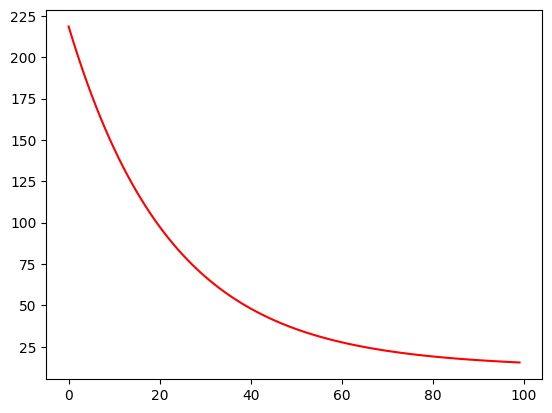

In [5]:
bgd_thetas, losses = batch_gradient_descent()

print(bgd_thetas[-1])

# in loss cho 100 sample đầu
x_axis = list(range(100))
plt.plot(x_axis, losses[:100], color="r")
plt.show()